Upload your Online Retail CSV dataset


Saving data.csv to data.csv

Original Dataset:
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

      InvoiceDate  UnitPrice  CustomerID         Country  
0  12/1/2010 8:26       2.55     17850.0  United Kingdom  
1  12/1/2010 8:26       3.39     17850.0  United Kingdom  
2  12/1/2010 8:26       2.75     17850.0  United Kingdom  
3  12/1/2010 8:26       3.39     17850.0  United Kingdom  
4  12/1/2010 8:26       3.39     17850.0  United Kingdom  

Shape: (541909, 8)

Cleaned Dataset:
Rows: 526054
Missing Values: 133914
Duplicates: 0

Selected Product: 23166

Daily Demand Data:
        Date  Demand
0 2011-01-18

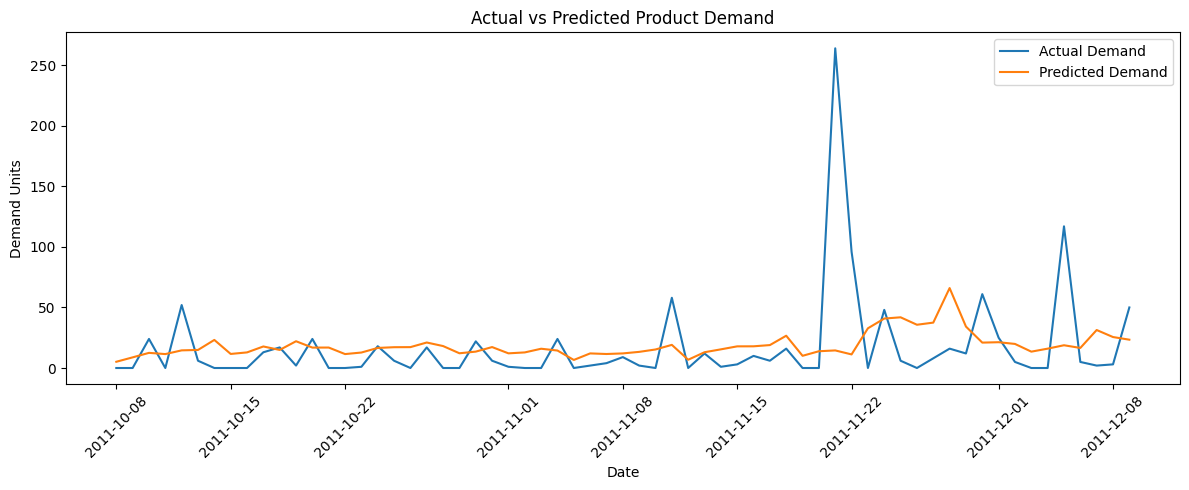

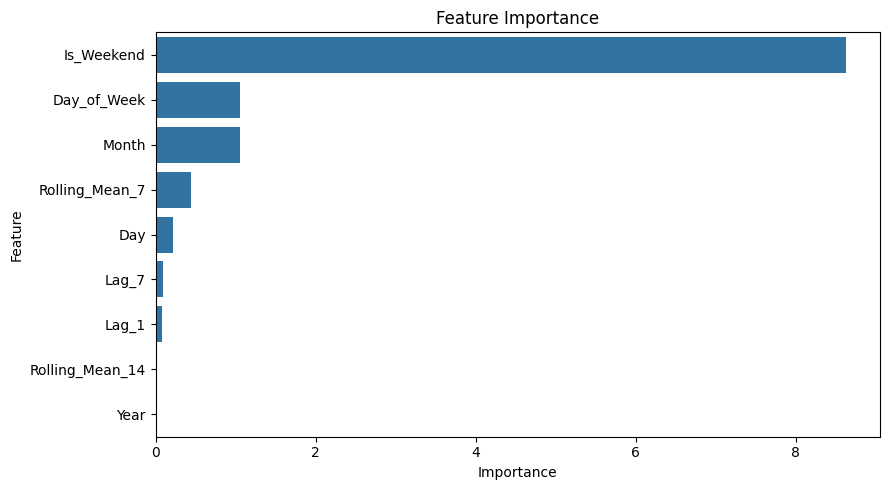

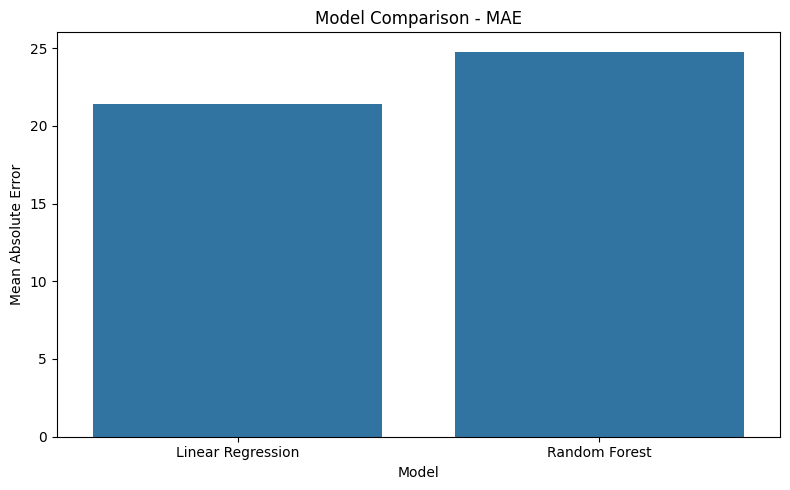

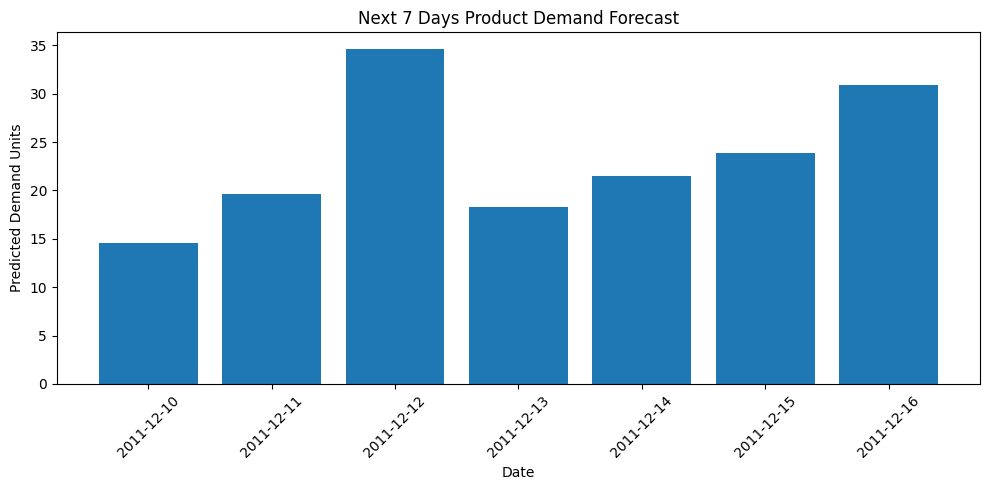


TASK 5: PREDICTIVE DEMAND MODELING - BUSINESS INSIGHTS

1. Selected Product:
   23166

2. Best Performing Model:
   Linear Regression

3. Linear Regression MAE:
   21.40 units

4. Random Forest MAE:
   24.77 units

5. Most Important Feature:
   Is_Weekend

6. Average Forecast Demand:
   23.34 units per day

7. Total Forecast Demand for Next 7 Days:
   163.39 units

8. Suggested Procurement Quantity:
   179.73 units
   (Includes an illustrative 10% planning buffer.)

9. Business Recommendation:
   The company can use the selected model's demand
   forecast to support inventory and procurement planning.
   The suggested quantity should also be checked against
   current stock, supplier lead time and safety stock.

10. Dataset Limitation:
    The dataset does not contain actual holiday or
    promotion information. These features were not
    included in model training.

11. Scope:
    This model forecasts one high-volume product.
    Forecasts are based on historical daily sales and
   

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:

# ============================================================
# TASK 5: PREDICTIVE DEMAND MODELING WITH FEATURE ENGINEERING
# Mavrista Technologies - Data Science Internship
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import zipfile
import warnings

from google.colab import files
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. UPLOAD DATASET
# ------------------------------------------------------------

print("Upload your Online Retail CSV dataset")
uploaded = files.upload()

file_name = list(uploaded.keys())[0]

try:
    df = pd.read_csv(file_name, encoding="ISO-8859-1")
except:
    df = pd.read_csv(file_name)

print("\nOriginal Dataset:")
print(df.head())
print("\nShape:", df.shape)

# ------------------------------------------------------------
# 2. DATA CLEANING
# ------------------------------------------------------------

df.columns = df.columns.str.strip()

required_columns = ["InvoiceDate", "StockCode", "Quantity"]

for col in required_columns:
    if col not in df.columns:
        raise ValueError(f"Required column missing: {col}")

df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"], errors="coerce"
)

df["Quantity"] = pd.to_numeric(
    df["Quantity"], errors="coerce"
)

df["StockCode"] = df["StockCode"].astype(str).str.strip()

df = df.dropna(
    subset=["InvoiceDate", "StockCode", "Quantity"]
)

# Remove cancelled invoices
if "InvoiceNo" in df.columns:
    df["InvoiceNo"] = df["InvoiceNo"].astype(str)
    df = df[~df["InvoiceNo"].str.startswith("C")]

# Keep valid sales quantities
df = df[df["Quantity"] > 0]

df = df.drop_duplicates()

print("\nCleaned Dataset:")
print("Rows:", len(df))
print("Missing Values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())

# ------------------------------------------------------------
# 3. SELECT A PRODUCT FOR DEMAND MODELING
# ------------------------------------------------------------

# Select the product with the most active transaction days to ensure enough historic time-series data
df['InvoiceDay'] = df['InvoiceDate'].dt.normalize()
product_active_days = df.groupby("StockCode")["InvoiceDay"].nunique()

# Filter products with at least 30 active days to allow proper modeling, then choose the highest volume among them
viable_products = product_active_days[product_active_days >= 30].index

if len(viable_products) > 0:
    selected_product = (
        df[df["StockCode"].isin(viable_products)]
        .groupby("StockCode")["Quantity"]
        .sum()
        .idxmax()
    )
else:
    # Fallback if no product has >= 30 days
    selected_product = product_active_days.idxmax()

print("\nSelected Product:", selected_product)

product_df = df[
    df["StockCode"] == selected_product
].copy()

# Aggregate quantity into daily demand
daily_demand = (
    product_df.groupby(
        product_df["InvoiceDate"].dt.normalize()
    )["Quantity"]
    .sum()
    .sort_index()
)

# Fill dates without sales with zero demand
date_range = pd.date_range(
    start=daily_demand.index.min(),
    end=daily_demand.index.max(),
    freq="D"
)

daily_demand = daily_demand.reindex(
    date_range, fill_value=0
)

data = pd.DataFrame({
    "Date": daily_demand.index,
    "Demand": daily_demand.values
})

print("\nDaily Demand Data:")
print(data.head())

# ------------------------------------------------------------
# 4. FEATURE ENGINEERING
# ------------------------------------------------------------

data["Day"] = data["Date"].dt.day
data["Day_of_Week"] = data["Date"].dt.dayofweek
data["Month"] = data["Date"].dt.month
data["Year"] = data["Date"].dt.year

# Weekend feature
data["Is_Weekend"] = (
    data["Day_of_Week"] >= 5
).astype(int)

# Lag features
data["Lag_1"] = data["Demand"].shift(1)
data["Lag_7"] = data["Demand"].shift(7)

# Rolling average features
data["Rolling_Mean_7"] = (
    data["Demand"].shift(1).rolling(window=7).mean()
)

data["Rolling_Mean_14"] = (
    data["Demand"].shift(1).rolling(window=14).mean()
)

data = data.dropna().reset_index(drop=True)

print("\nFeature Engineered Data:")
print(data.head())

# ------------------------------------------------------------
# 5. PREPARE FEATURES AND TARGET
# ------------------------------------------------------------

features = [
    "Day",
    "Day_of_Week",
    "Month",
    "Year",
    "Is_Weekend",
    "Lag_1",
    "Lag_7",
    "Rolling_Mean_7",
    "Rolling_Mean_14"
]

X = data[features]
y = data["Demand"]

# ------------------------------------------------------------
# 6. TIME-AWARE TRAIN TEST SPLIT
# ------------------------------------------------------------

split_index = int(len(data) * 0.80)

if split_index < 10 or len(data) - split_index < 2:
    raise ValueError(
        f"Not enough daily records ({len(data)}) for reliable time-based validation. Please use a dataset covering a longer time range."
    )

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

test_dates = data["Date"].iloc[split_index:]

print("\nTraining Records:", len(X_train))
print("Testing Records:", len(X_test))

print("Training Period:",
      data["Date"].iloc[0],
      "to",
      data["Date"].iloc[split_index - 1])

print("Testing Period:",
      data["Date"].iloc[split_index],
      "to",
      data["Date"].iloc[-1])

# ------------------------------------------------------------
# 7. TRAIN TWO MACHINE LEARNING MODELS
# ------------------------------------------------------------

linear_model = LinearRegression()

random_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    max_depth=10,
    min_samples_leaf=2,
    n_jobs=-1
)

linear_model.fit(X_train, y_train)
random_model.fit(X_train, y_train)

# Predictions
linear_predictions = np.maximum(
    linear_model.predict(X_test), 0
)

random_predictions = np.maximum(
    random_model.predict(X_test), 0
)

# ------------------------------------------------------------
# 8. MODEL EVALUATION
# ------------------------------------------------------------

linear_mae = mean_absolute_error(
    y_test, linear_predictions
)

linear_rmse = np.sqrt(
    mean_squared_error(y_test, linear_predictions)
)

random_mae = mean_absolute_error(
    y_test, random_predictions
)

random_rmse = np.sqrt(
    mean_squared_error(y_test, random_predictions)
)

comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [linear_mae, random_mae],
    "RMSE": [linear_rmse, random_rmse]
})

print("\nMODEL COMPARISON")
print(comparison)

# Select model based on lower MAE
if random_mae <= linear_mae:
    best_model = random_model
    best_model_name = "Random Forest"
    best_predictions = random_predictions
else:
    best_model = linear_model
    best_model_name = "Linear Regression"
    best_predictions = linear_predictions

print("\nBest Model:", best_model_name)

print(
    "Average prediction error:",
    round(min(linear_mae, random_mae), 2),
    "units per day (MAE)"
)

# ------------------------------------------------------------
# 9. FEATURE IMPORTANCE
# ------------------------------------------------------------

if best_model_name == "Random Forest":
    importance_values = best_model.feature_importances_
else:
    importance_values = np.abs(best_model.coef_)

feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": importance_values
})

feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
)

print("\nFEATURE IMPORTANCE")
print(feature_importance)

# ------------------------------------------------------------
# 10. DEMAND PREDICTION REPORT
# ------------------------------------------------------------

prediction_report = pd.DataFrame({
    "Date": test_dates.values,
    "Actual_Demand": y_test.values,
    "Predicted_Demand": best_predictions
})

prediction_report["Prediction_Error"] = (
    prediction_report["Actual_Demand"]
    - prediction_report["Predicted_Demand"]
)

print("\nDEMAND PREDICTIONS")
print(prediction_report.head(10))

# ------------------------------------------------------------
# 11. NEXT 7 DAYS DEMAND FORECAST
# ------------------------------------------------------------

history = pd.Series(
    daily_demand.values.astype(float),
    index=daily_demand.index
)

future_records = []

for i in range(7):
    next_date = history.index[-1] + pd.Timedelta(days=1)

    day = next_date.day
    day_of_week = next_date.dayofweek
    month = next_date.month
    year = next_date.year
    is_weekend = int(day_of_week >= 5)

    lag_1 = history.iloc[-1]
    lag_7 = history.iloc[-7] if len(history) >= 7 else 0

    rolling_7 = history.iloc[-7:].mean()
    rolling_14 = history.iloc[-14:].mean()

    new_row = pd.DataFrame([[
        day,
        day_of_week,
        month,
        year,
        is_weekend,
        lag_1,
        lag_7,
        rolling_7,
        rolling_14
    ]], columns=features)

    predicted_demand = max(
        0, float(best_model.predict(new_row)[0])
    )

    # Add predicted demand to history for next forecast
    history.loc[next_date] = predicted_demand

    future_records.append({
        "Date": next_date,
        "Predicted_Demand": round(predicted_demand, 2)
    })

future_forecast = pd.DataFrame(future_records)

print("\nNEXT 7 DAYS FORECAST")
print(future_forecast)

# ------------------------------------------------------------
# 12. PROCUREMENT RECOMMENDATION
# ------------------------------------------------------------

average_forecast = future_forecast[
    "Predicted_Demand"
].mean()

total_forecast = future_forecast[
    "Predicted_Demand"
].sum()

recommended_quantity = total_forecast * 1.10

recommendation = pd.DataFrame({
    "Product": [selected_product],
    "Forecast_Period": ["Next 7 Days"],
    "Forecast_Total_Units": [round(total_forecast, 2)],
    "Average_Daily_Demand": [round(average_forecast, 2)],
    "Suggested_Quantity_With_10_Percent_Buffer": [
        round(recommended_quantity, 2)
    ],
    "Selected_Model": [best_model_name]
})

print("\nPROCUREMENT RECOMMENDATION")
print(recommendation)

# ------------------------------------------------------------
# 13. VISUALIZATIONS
# ------------------------------------------------------------

os.makedirs("Task_5_Reports", exist_ok=True)

# Actual vs Predicted Demand
plt.figure(figsize=(12, 5))

plt.plot(
    test_dates,
    y_test.values,
    label="Actual Demand"
)

plt.plot(
    test_dates,
    best_predictions,
    label="Predicted Demand"
)

plt.title("Actual vs Predicted Product Demand")
plt.xlabel("Date")
plt.ylabel("Demand Units")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "Task_5_Reports/Actual_vs_Predicted.png"
)
plt.show()

# Feature Importance
plt.figure(figsize=(9, 5))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance")
plt.tight_layout()

plt.savefig(
    "Task_5_Reports/Feature_Importance.png"
)
plt.show()

# Model Comparison
plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparison,
    x="Model",
    y="MAE"
)

plt.title("Model Comparison - MAE")
plt.ylabel("Mean Absolute Error")
plt.tight_layout()

plt.savefig(
    "Task_5_Reports/Model_Comparison.png"
)
plt.show()

# Next 7 Days Forecast
plt.figure(figsize=(10, 5))

plt.bar(
    future_forecast["Date"].astype(str),
    future_forecast["Predicted_Demand"]
)

plt.title("Next 7 Days Product Demand Forecast")
plt.xlabel("Date")
plt.ylabel("Predicted Demand Units")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "Task_5_Reports/Next_7_Days_Forecast.png"
)
plt.show()

# ------------------------------------------------------------
# 14. BUSINESS INSIGHTS
# ------------------------------------------------------------

top_feature = feature_importance.iloc[0]["Feature"]

insights = f"""
TASK 5: PREDICTIVE DEMAND MODELING - BUSINESS INSIGHTS

1. Selected Product:
   {selected_product}

2. Best Performing Model:
   {best_model_name}

3. Linear Regression MAE:
   {linear_mae:.2f} units

4. Random Forest MAE:
   {random_mae:.2f} units

5. Most Important Feature:
   {top_feature}

6. Average Forecast Demand:
   {average_forecast:.2f} units per day

7. Total Forecast Demand for Next 7 Days:
   {total_forecast:.2f} units

8. Suggested Procurement Quantity:
   {recommended_quantity:.2f} units
   (Includes an illustrative 10% planning buffer.)

9. Business Recommendation:
   The company can use the selected model's demand
   forecast to support inventory and procurement planning.
   The suggested quantity should also be checked against
   current stock, supplier lead time and safety stock.

10. Dataset Limitation:
    The dataset does not contain actual holiday or
    promotion information. These features were not
    included in model training.

11. Scope:
    This model forecasts one high-volume product.
    Forecasts are based on historical daily sales and
    should be reviewed before actual procurement.
"""

print(insights)

# ------------------------------------------------------------
# 15. SAVE ALL OUTPUT FILES
# ------------------------------------------------------------

data.to_csv(
    "Task_5_Cleaned_Demand_Data.csv",
    index=False
)

comparison.to_csv(
    "Task_5_Model_Comparison.csv",
    index=False
)

prediction_report.to_csv(
    "Task_5_Demand_Predictions.csv",
    index=False
)

feature_importance.to_csv(
    "Task_5_Feature_Importance.csv",
    index=False
)

future_forecast.to_csv(
    "Task_5_Next_7_Days_Forecast.csv",
    index=False
)

recommendation.to_csv(
    "Task_5_Procurement_Recommendation.csv",
    index=False
)

with open(
    "Task_5_Reports/Task_5_Business_Insights.txt",
    "w"
) as file:
    file.write(insights)

# ------------------------------------------------------------
# 16. CREATE ZIP FILE
# ------------------------------------------------------------

output_files = [
    "Task_5_Cleaned_Demand_Data.csv",
    "Task_5_Model_Comparison.csv",
    "Task_5_Demand_Predictions.csv",
    "Task_5_Feature_Importance.csv",
    "Task_5_Next_7_Days_Forecast.csv",
    "Task_5_Procurement_Recommendation.csv"
]

with zipfile.ZipFile(
    "Task_5_Analysis_Reports.zip",
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    for file in output_files:
        zipf.write(file)

    for root, dirs, files_list in os.walk("Task_5_Reports"):
        for file in files_list:
            path = os.path.join(root, file)
            zipf.write(path)

print("\nTASK 5 COMPLETED SUCCESSFULLY!")

# Download ZIP
files.download("Task_5_Analysis_Reports.zip")
